# 3B. Autoencoder - MVTec AD (bottle)
Convolutional autoencoder on MVTec bottle. Train on defect-free images, detect defects via reconstruction error.

In [1]:
import glob
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score, classification_report

keras.utils.set_random_seed(0)

In [2]:
SIZE = 64
ROOT = "../datasets/AutoEncoder/MVTec/bottle"

def load(paths):
    arr = np.stack([np.asarray(Image.open(p).convert("RGB").resize((SIZE, SIZE))) for p in paths])
    return (arr / 255.0).astype("float32")

train_paths = sorted(glob.glob(f"{ROOT}/train/good/*.png"))
test_good = sorted(glob.glob(f"{ROOT}/test/good/*.png"))
test_bad = sorted(glob.glob(f"{ROOT}/test/*/*.png"))
test_bad = [p for p in test_bad if "/good/" not in p]

x_train = load(train_paths)
x_test = load(test_good + test_bad)
y_test = np.array([0]*len(test_good) + [1]*len(test_bad))
print("train:", x_train.shape, "test:", x_test.shape, "defects:", y_test.sum())

train: (50, 64, 64, 3) test: (24, 64, 64, 3) defects: 18


In [3]:
model = keras.Sequential([
    layers.Input(shape=(SIZE, SIZE, 3)),
    layers.Conv2D(16, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2D(32, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2D(64, 3, strides=2, padding="same", activation="relu"),
    layers.Flatten(),
    layers.Dense(32, activation="relu"),
    layers.Dense(8*8*64, activation="relu"),
    layers.Reshape((8, 8, 64)),
    layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2DTranspose(16, 3, strides=2, padding="same", activation="relu"),
    layers.Conv2DTranspose(3, 3, strides=2, padding="same", activation="sigmoid"),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 16)     │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │       131,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4096)           │       135,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 16)     │         4,624 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 3)      │           435 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 313,379 (1.20 MB)

 Trainable params: 313,379 (1.20 MB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train, x_train, epochs=100, batch_size=8, validation_split=0.1, verbose=0)
print("final loss:", history.history["loss"][-1], "val_loss:", history.history["val_loss"][-1])

final loss: 0.0014698196901008487 val_loss: 0.0016605114797130227


In [5]:
recon = model.predict(x_test, batch_size=8)
pix_err = ((x_test - recon) ** 2).mean(axis=-1)
err = pix_err.mean(axis=(1, 2))

auc = roc_auc_score(y_test, err)
threshold = np.median(err[y_test == 0])
y_pred = (err > threshold).astype(int)

print(f"AUC: {auc:.4f}")
print(classification_report(y_test, y_pred, target_names=["good", "defect"]))

1/3 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 


AUC: 0.7593
              precision    recall  f1-score   support

        good       0.38      0.50      0.43         6
      defect       0.81      0.72      0.76        18

    accuracy                           0.67        24
   macro avg       0.59      0.61      0.60        24
weighted avg       0.70      0.67      0.68        24



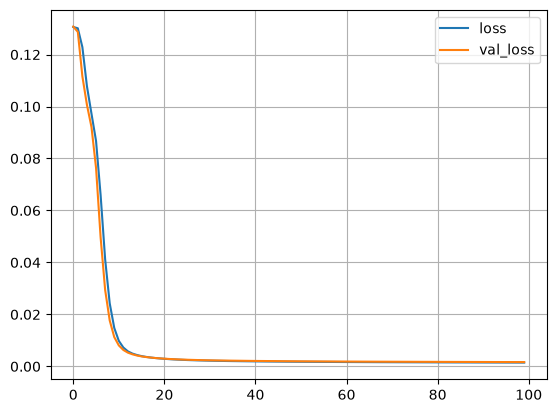

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()

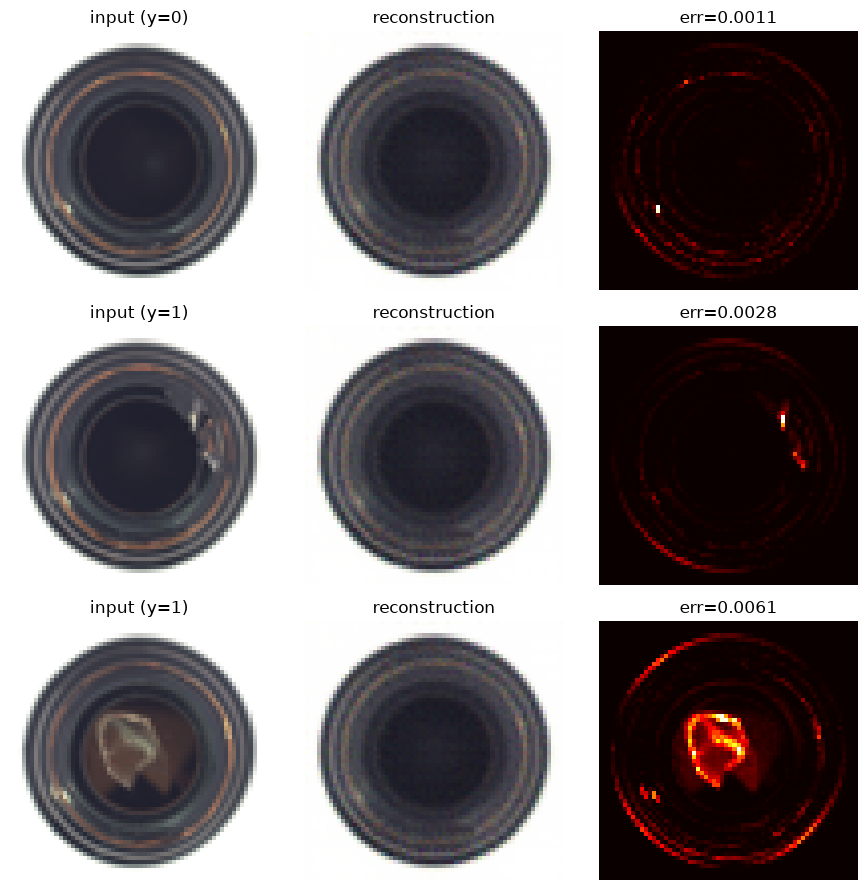

In [7]:
order = np.argsort(err)
picks = [order[0], order[len(order)//2], order[-1]]
fig, ax = plt.subplots(len(picks), 3, figsize=(9, 3*len(picks)))
for row, i in enumerate(picks):
    ax[row,0].imshow(x_test[i]);        ax[row,0].set_title(f"input (y={y_test[i]})")
    ax[row,1].imshow(recon[i]);         ax[row,1].set_title("reconstruction")
    ax[row,2].imshow(pix_err[i], cmap="hot"); ax[row,2].set_title(f"err={err[i]:.4f}")
    for a in ax[row]: a.axis("off")
plt.tight_layout(); plt.show()